#PyTroch Workflow

Let's explore a anexmaple PyTorch end-to-end workflow



In [29]:
what_were_covering = {
    1: "data (prepare and load)",
    2: "build model",
    3: "fitting the model to data (training)",
    4: "making predictions and evaluating a model (inference)",
    5: "saving and loading a model",
    6: "putting it all together"
}

what_were_covering

{1: 'data (prepare and load)',
 2: 'build model',
 3: 'fitting the model to data (training)',
 4: 'making predictions and evaluating a model (inference)',
 5: 'saving and loading a model',
 6: 'putting it all together'}

In [3]:
import torch
import numpy as np
from torch import nn #nn contains all of Pytorch's building blocks for
import matplotlib.pyplot as plt

#Check Pytorch version
torch.__version__


'2.11.0+cpu'

## 1. Data (preparing and loading)

Data can be almost anything... in machine learning.

- Excel spreadsheet
- Images of any kind
- Videos (YouTube has lots of data...)
- Audio like songs or podcasts
- DNA
- Text

Machine learning is a game of two parts:

1. Get data into a numerical representation.
2. Build a model to learn patterns in that numerical representation.

To showcase this, let's create some *known* data using the linear regression formula.

We'll use a linear regression formula to make a straight line with *known parameters*.

In [4]:
#create *known* parameters
weight=0.7
bias=0.3

#Create
start=0
end=1
step=0.02
X=torch.arange(start,end,step).unsqueeze(dim=1)
y=weight*X+bias

X[:10],y[:10],len(X),len(y)

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]),
 50,
 50)

###Splitting data into training andest sets(one of the most important concepts in machine learning in general)

Let's create a training and test set with our data.


In [5]:
# Create a trian/test split

train_split=int(0.8*len(X))

X_train,y_train=X[:train_split],y[:train_split]
X_test,y_test=X[train_split:],y[train_split:]

len(X_train),len(y_train),len(X_test),len(y_test)


(40, 40, 10, 10)

how might we better visualize our data?

This is where the data explorer's motto comes in!
"Visualize,visualize,visualize!"

In [6]:
def plot_predictions(train_data=X_train,
                     train_labels=y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None):

      """
      Plots training data,test,data and compares predictions.
      """

      plt.figure(figsize=(10,7))

      #Plot traning data in blue
      plt.scatter(train_data,train_labels,c="b",s=4,label="training data")

      #Plot test data in green
      plt.scatter(test_data,test_labels,c="g",s=4,label="test data")

      #Are there predictions?
      if predictions is not None:
        #Plot the predictions if they exist
        plt.scatter(test_data,predictions,c="r",s=4,label="Predictions")

      #Show the legend
      plt.legend(prop={"size":14});



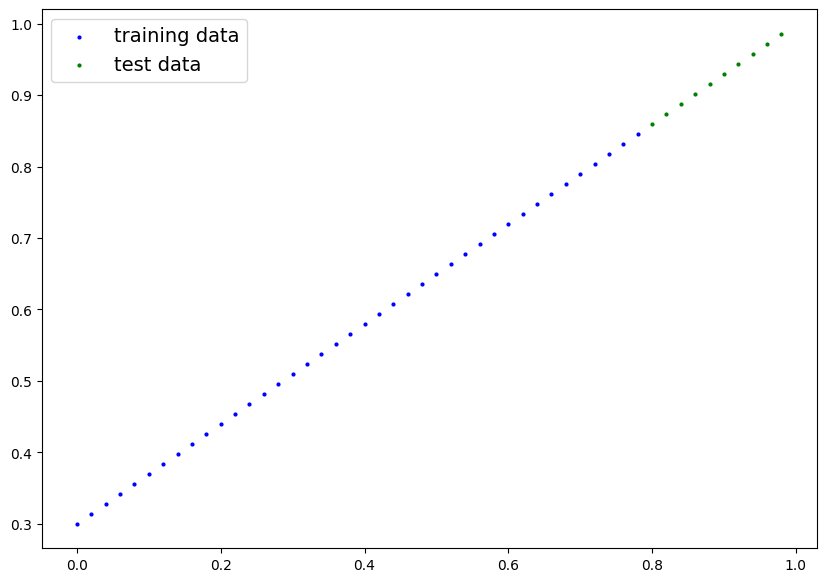

In [7]:
plot_predictions()

##Build  model

Our first Pytorch model!

This is very exciting...let's do it!

What our mode ldoes:
* Start with random values(weight &bias)
* Look at Traning data and adjust the random values to better represent(or get closer to )the ideal values(weight & bias values we used to create the data)

How does it do so?

Through two main algorithms:

1. Gradient descent
2. Backpropagation


In [8]:
from torch import nn

#Create linear regression model class
class LinearRegressionModel(nn.Module):#almost everything in PyTorch inherit nn.Module
      def __init__(self):
          super().__init__()
          self.weight=nn.Parameter(torch.randn(1,requires_grad=True,
                                                dtype=torch.float))

          self.bias=nn.Parameter(torch.randn(1,requires_grad=True,
                                            dtype=torch.float))

          #Forward method to define the computatoin in the model

      def forward(self,x:torch.Tensor)->torch.Tensor:#<- "x" is the input data
        return self.weight*x+self.bias#this is the linear regression




## PyTorch model building essentials

- `torch.nn` - contains all of the buildings for computational graphs (a neural network can be considered a computational graph)
- `torch.nn.Parameter` - what parameters should our model try and learn, often a PyTorch layer from `torch.nn` will set these for us
- `torch.nn.Module` - The base class for all neural network modules, if you subclass it, you should overwrite `forward()`
- `torch.optim` - this is where the optimizers in PyTorch live, they will help with gradient descent
- `def forward()` - All `nn.Module` subclasses require you to overwrite `forward()`, this method defines what happens in the forward computation


* cheat sheet:https://pytorch-cn.com/tutorials/beginner/ptcheat.html

In [9]:
torch.randn(1)

tensor([-0.6439])

## Checking the contents of our PyTorch model

Now we've created a model, let's see what's inside...

So we can check our model parameters or what's inside our model using `.parameters()`.

In [10]:
# Create a random seed
torch.manual_seed(42)

#Create an instance of the model (this is a subclass of nn.Module)
model_0=LinearRegressionModel()

#Check out the parameters
list(model_0.parameters())


[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [11]:
#List named parameters
model_0.state_dict()


OrderedDict([('weight', tensor([0.3367])), ('bias', tensor([0.1288]))])

### Making prediction using `torch.inference_mode()`

To check our model's predictive power,let's see how well it predicts `y_test` based on `X_test`.

When we pass data through our model,it's going to run it through the `forward()` method

In [12]:
X_test,y_test

(tensor([[0.8000],
         [0.8200],
         [0.8400],
         [0.8600],
         [0.8800],
         [0.9000],
         [0.9200],
         [0.9400],
         [0.9600],
         [0.9800]]),
 tensor([[0.8600],
         [0.8740],
         [0.8880],
         [0.9020],
         [0.9160],
         [0.9300],
         [0.9440],
         [0.9580],
         [0.9720],
         [0.9860]]))

In [13]:
#Make predictions with model
with torch.inference_mode():#makeing prediction
    y_preds=model_0(X_test)

y_preds


tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

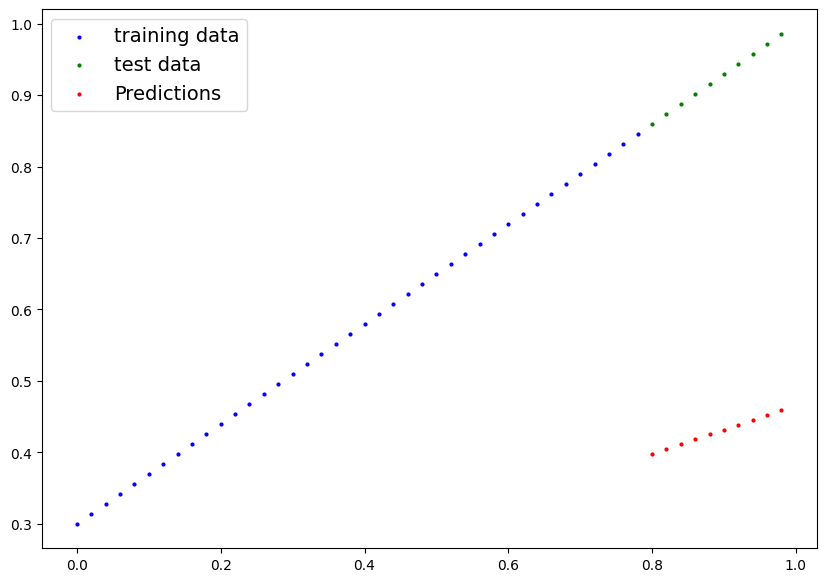

In [14]:
plot_predictions(predictions=y_preds)

## 3. Train model

The whole idea of training is for a model to move from some **unknown parameters** (these may be random) to some **known parameters**.

Or in other words from a poor representation of the data to a better representation of the data.

One way to measure how poor or how wrong your model's predictions are is to use a **loss function**.

- **Note:** Loss function may also be called **cost function** or **criterion** in different areas. For our case, we're going to refer to it as a loss function.
- **Loss function:** A function to measure how wrong your model's predictions are to the ideal outputs. Lower is better.
* **Optimizer:** Takes into account the loss of a model and adjusts the model's parameters (e.g. weight & bias)

and specifically for PyTorch, we need:
* A training loop
* A testing loop

In [15]:
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [16]:
#Check ut our model's parameter(a parameter is a value that the model sets itself)
model_0.state_dict()

OrderedDict([('weight', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [17]:
#setup a loss function
loss_fn=nn.L1Loss()

#Setup an optimizer(stochastic gradient descent)
optimizer=torch.optim.SGD(params=model_0.parameters(),lr=0.01) #lr=learning rate=possibly the most important hyperparameter you can set


###Building a training loop(and a testing loop) in PyTorch

A couple of things we need in a training loop:

0. loop through the data
1. Forward pass(this involves data moving through our model's `forward()` functions) to make predictions on data -also called forward propagation
2. Calculate the loss(compare forward pass predictions to ground truth labels)
3. Optimizer zero grad
4. Loss backward
5. Optimizer step -use the optimizer to adjust our model's parameters to try and improve the loss (**gradient descent**)

In [18]:
X_test,y_test

(tensor([[0.8000],
         [0.8200],
         [0.8400],
         [0.8600],
         [0.8800],
         [0.9000],
         [0.9200],
         [0.9400],
         [0.9600],
         [0.9800]]),
 tensor([[0.8600],
         [0.8740],
         [0.8880],
         [0.9020],
         [0.9160],
         [0.9300],
         [0.9440],
         [0.9580],
         [0.9720],
         [0.9860]]))

In [19]:
with torch.no_grad():
  list(model_0.parameters())

In [20]:
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [21]:
torch.manual_seed(42)


# An epoch is one loop through the data...(this is a hyperparameter because we've set )
epochs=200

#Track different values

epoch_count=[]
loss_values=[]
test_loss_values=[]


###Training
# 0. Loop through the data
for epoch in range(epochs):
    #Set the model to training mpde
    model_0.train() #train mode in PyTorch set all parameters that require gradients to require gradients

    #1.Forward pass
    y_pred=model_0(X_train)

    #2.Calculate the loss
    loss=loss_fn(y_pred,y_train)
    print(f"Loss: {loss}")

    #3.Optimizer zero grad
    optimizer.zero_grad()

    #4.Perfrom backpropagation on the loss with respect to the parameters of the model
    loss.backward()

    #5.Step the optimizer(perfrom gradient descent)
    optimizer.step() #by default how the optimizer changes will acculumate through the loop so... we have to zero them above in steo 3 for the next iteration of the loop


    #testing
    model_0.eval() #turns off gradient tracking
    with torch.inference_mode():#turn off gradient tracking & a couple more things behind the scenes
    #with torch.no_grad():#you may also see torch.no_grad() in older PyTorch code
      #1.Do the forward pass
      test_pred=model_0(X_test)
      #2.Calculate the loss
      test_loss=loss_fn(test_pred,y_test)


    #Print out what's happenin'
    if(epoch%10==0):
      epoch_count.append(epoch)
      loss_values.append(loss)
      test_loss_values.append(test_loss)
      print(f"Epoch:{epoch} | Loss:{loss} | Test loss:{test_loss}")
      #Print out model state_dict(
      print(model_0.state_dict())




Loss: 0.31288138031959534
Epoch:0 | Loss:0.31288138031959534 | Test loss:0.48106518387794495
OrderedDict({'weight': tensor([0.3406]), 'bias': tensor([0.1388])})
Loss: 0.3013603389263153
Loss: 0.28983935713768005
Loss: 0.2783183455467224
Loss: 0.26679736375808716
Loss: 0.2552763521671295
Loss: 0.24375534057617188
Loss: 0.23223432898521423
Loss: 0.22071333229541779
Loss: 0.20919232070446014
Loss: 0.1976713240146637
Epoch:10 | Loss:0.1976713240146637 | Test loss:0.3463551998138428
OrderedDict({'weight': tensor([0.3796]), 'bias': tensor([0.2388])})
Loss: 0.18615034222602844
Loss: 0.1746293306350708
Loss: 0.16310831904411316
Loss: 0.1515873372554779
Loss: 0.14006635546684265
Loss: 0.1285453587770462
Loss: 0.11702437698841095
Loss: 0.1060912236571312
Loss: 0.09681284427642822
Loss: 0.08908725529909134
Epoch:20 | Loss:0.08908725529909134 | Test loss:0.21729660034179688
OrderedDict({'weight': tensor([0.4184]), 'bias': tensor([0.3333])})
Loss: 0.08227583020925522
Loss: 0.07638873159885406
Loss:

/tmp/ipykernel_1961/2254571577.py:2: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  plt.plot(epoch_count,np.array(torch.tensor(loss_values).cpu().numpy()),label="Train loss")


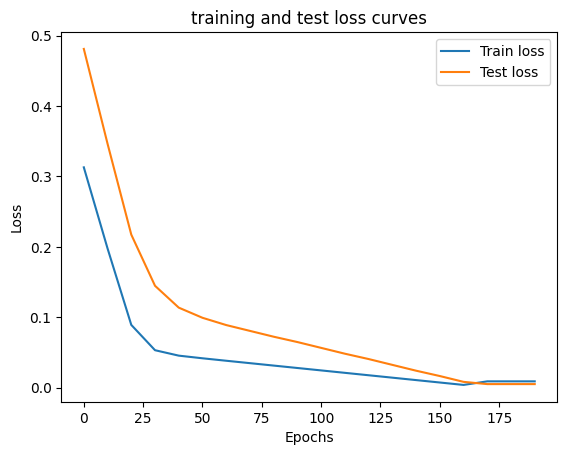

In [22]:
#Plot the loss curves
plt.plot(epoch_count,np.array(torch.tensor(loss_values).cpu().numpy()),label="Train loss")
plt.plot(epoch_count,test_loss_values,label="Test loss")
plt.title("training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend()

In [23]:
with torch.inference_mode():
  y_preds_new=model_0(X_test)

In [24]:
model_0.state_dict()

OrderedDict([('weight', tensor([0.6990])), ('bias', tensor([0.3093]))])

In [25]:
weight,bias

(0.7, 0.3)

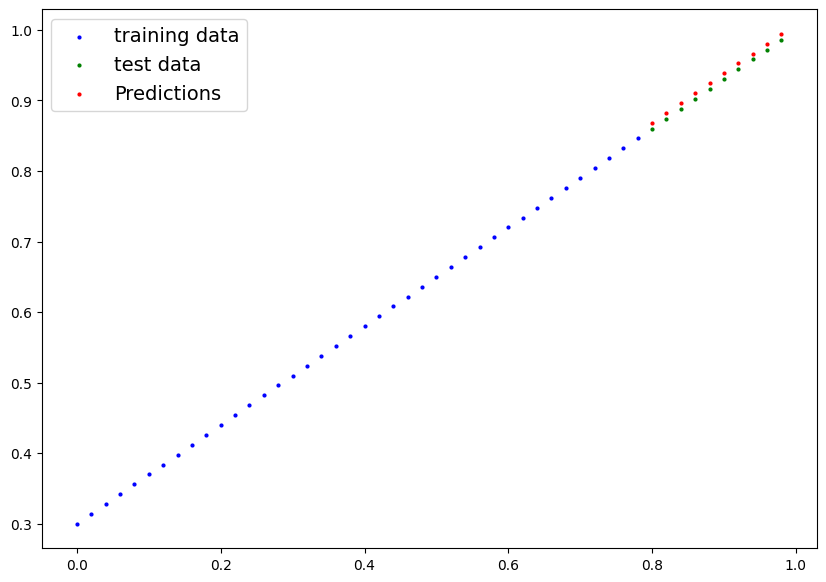

In [26]:
plot_predictions(predictions=y_preds_new);

## Saving a model in PyTorch

there are three man methods you should about for saving and loading models in PyTorch.

1.`torch.save()` -allows you save a PyTorch object in Python's pickle format

2.`torch.load()`- allows you load a saved PyTorch object

3.`torch.nn.Module.load_state_dict()`-this allows to load a model's saved state dictionary


In [27]:
# saving our PyTorch model
from pathlib import Path

#1.Create models directiory

MODEL_PATH=Path("models")
MODEL_PATH.mkdir(parents=True,exist_ok=True)


#2.Create model save path
MODEL_NAME="01_pytorch_workflow_model_0.pth"
MODEL_SAVE_PATH=MODEL_PATH/MODEL_NAME

#3. Save the model state dict

torch.save(obj=model_0.state_dict(),f=MODEL_SAVE_PATH)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [28]:
!ls -l models

total 4
-rw-r--r-- 1 root root 2117 Sep 12 07:03 01_pytorch_workflow_model_0.pth


## Loading a PyTorch model

Since we saved our model's `state_dict()` rather than the entire model, we'll create a new instance of our model class and load the saved `state_dict()` into that.

In [30]:
model_0.state_dict()

OrderedDict([('weight', tensor([0.6990])), ('bias', tensor([0.3093]))])

In [33]:
#to laod in a saved state_dict we have to instantiate a new instance of our model class

loaded_model_0=LinearRegressionModel()

#Load the saved state_dict() of model_0 (this will update the new instance with updated parameters)
loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH))


In [34]:
loaded_model_0.state_dict()

OrderedDict([('weight', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [35]:
#Make some predictions with our loaded model

loaded_model_0.eval() #這是把模型切換成 evaluation mode（評估模式）。
with torch.inference_mode():#這段運算不用計算 gradient。
  loaded_model_preds=loaded_model_0(X_test)

loaded_model_preds

tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

In [36]:
#Comapre loaded model preds with original model preds
y_preds==loaded_model_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

## 6.putting it all together

let's go back through the steps above and see it all in one place.

In [3]:
# import Pytorch and matplotlib
import torch
from torch import nn
import matplotlib.pyplot as plt

#Check Pytorch version
torch.__version__

'2.11.0+cu128'

Create device-agnostic code.

This means if we've got access to a GPU,our code will use it (for potentially faster computing).If no GPU is available ,the code will default to using CPU.

In [4]:
# Setup device agnostic code
device="cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device:{device}")



Using device:cuda


### 6.1 Data

In [5]:
#Create some data using the linear regression formula of y=weight*X+bias
weight=0.7
bias=0.3

#Create range values
start=0
end=1
step=0.02

#Create X and Y (features and labels)

X=torch.arange(start,end,step).unsqueeze(dim=1) #without unsqueeze,errors will pop
y=weight*X+bias
X[:10],y[:10] # 前10



(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [6]:
#Split data 訓練集 跟 測試集
train_split=int(0.8 * len(X))
X_train,y_train=X[:train_split],y[:train_split] # front 80%
X_test,y_test=X[train_split:],y[train_split:]# back 20%
len(X_train),len(y_train),len(X_test),len(y_test)

(40, 40, 10, 10)

In [7]:
def plot_predictions(train_data=X_train,
                     train_labels=y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None):

      """
      Plots training data,test,data and compares predictions.
      """

      plt.figure(figsize=(10,7))

      #Plot traning data in blue
      plt.scatter(train_data,train_labels,c="b",s=4,label="Training data")

      #Plot test data in green
      plt.scatter(test_data,test_labels,c="g",s=4,label="Test data")

      #Are there predictions?
      if predictions is not None:
        #Plot the predictions if they exist
        plt.scatter(test_data,predictions,c="r",s=4,label="Predictions")

      #Show the legend
      plt.legend(prop={"size":14});


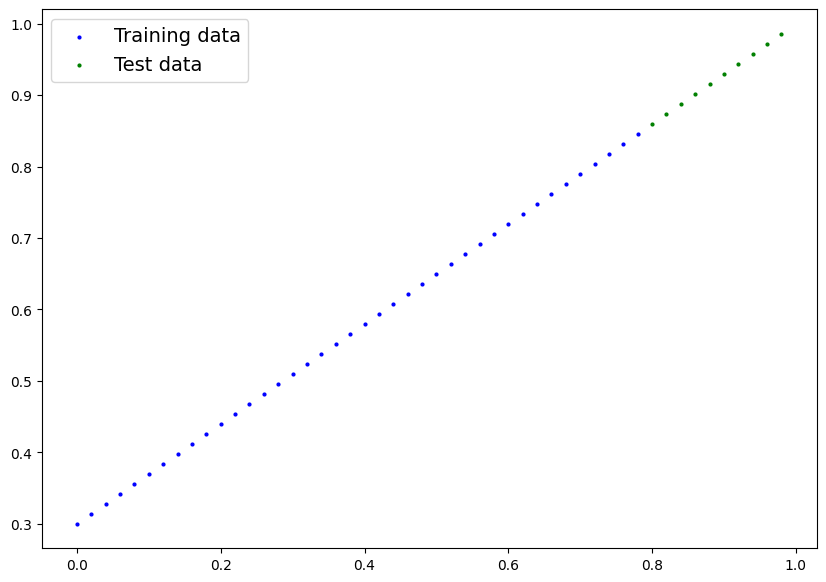

In [8]:
#Plot the data
#Note :if you don't have the plot_prediction() function loaded,this will error
plot_predictions(X_train,y_train,X_test,y_test)

## 6.2 Building a PyTorch Linear model

In [9]:
#create a kinear model by subclassing nn.Module
class LinearRegressionModelV2(nn.Module):
    def __init__(self):
      super().__init__()
      #Use nn.Linear() for creating the model parameters /also called:liner tranfrom
      self.linear_layer=nn.Linear(in_features=1,
                                  out_features=1)


    def forward(self,x:torch.Tensor)->torch.Tensor:
      return self.linear_layer(x)

#set the manual seed
torch.manual_seed(42)
model_1=LinearRegressionModelV2()
model_1,model_1.state_dict()





(LinearRegressionModelV2(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

In [10]:
model_1.to(device)#to will send the model to gpu
next(model_1.parameters()).device

device(type='cuda', index=0)

### 6.3 Training

For training we need:
* Loss function
* Optimizer
* Training loop
* Testing loop

In [11]:
#setup a loss function
loss_fn=nn.L1Loss()

#Setup an optimizer(stochastic gradient descent)
optimizer=torch.optim.SGD(params=model_1.parameters(),lr=0.01) #lr=learning rate=possibly the most important hyperparameter you can set


In [12]:
#Let's write a training loop

torch.manual_seed(42)

epochs=200

#Put data on the target device(device agnostic code for data)

X_train=X_train.to(device)
y_train=y_train.to(device)
X_test=X_test.to(device)
y_test=y_test.to(device)

for epoch in range(epochs):
  model_1.train()

  #1.Forward pass
  y_pred=model_1(X_train)

  #2.Calculate the loss
  loss=loss_fn(y_pred,y_train)

  #3. Optimizers zero grad
  optimizer.zero_grad() # 清除上一輪 gradient

  #4. Perfrom backpropagation
  loss.backward() # 算 ∂loss/∂weight、∂loss/∂bias

  # 5.OPtimizer step
  optimizer.step() # 根據 gradient 更新 weight、bias

  #Testing
  model_1.eval()
  with torch.inference_mode():
    test_pred=model_1(X_test)
    test_loss=loss_fn(test_pred,y_test)

  #Print out what's happening

  if epoch % 10==0:
      print(f"Epoch:{epoch} | Loss: {loss} | Test loss:{test_loss}")


Epoch:0 | Loss: 0.5551779270172119 | Test loss:0.5739762187004089
Epoch:10 | Loss: 0.4399681091308594 | Test loss:0.4392664134502411
Epoch:20 | Loss: 0.3247582018375397 | Test loss:0.30455657839775085
Epoch:30 | Loss: 0.20954833924770355 | Test loss:0.16984669864177704
Epoch:40 | Loss: 0.09433844685554504 | Test loss:0.03513690456748009
Epoch:50 | Loss: 0.023886388167738914 | Test loss:0.04784907028079033
Epoch:60 | Loss: 0.019956795498728752 | Test loss:0.045803118497133255
Epoch:70 | Loss: 0.016517987474799156 | Test loss:0.037530567497015
Epoch:80 | Loss: 0.013089174404740334 | Test loss:0.02994490973651409
Epoch:90 | Loss: 0.009653178043663502 | Test loss:0.02167237363755703
Epoch:100 | Loss: 0.006215683650225401 | Test loss:0.014086711220443249
Epoch:110 | Loss: 0.00278724217787385 | Test loss:0.005814164876937866
Epoch:120 | Loss: 0.0012645035749301314 | Test loss:0.013801801018416882
Epoch:130 | Loss: 0.0012645035749301314 | Test loss:0.013801801018416882
Epoch:140 | Loss: 0.001

In [13]:
model_1.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.6968]], device='cuda:0')),
             ('linear_layer.bias', tensor([0.3025], device='cuda:0'))])

In [14]:
weight,bias

(0.7, 0.3)

### 6.4 Making and evaluting predictions

In [15]:
# Turn model into evalution mode
model_1.eval()

#Make predictions on the test data
with torch.inference_mode():
  y_preds=model_1(X_test)

y_preds

tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]], device='cuda:0')

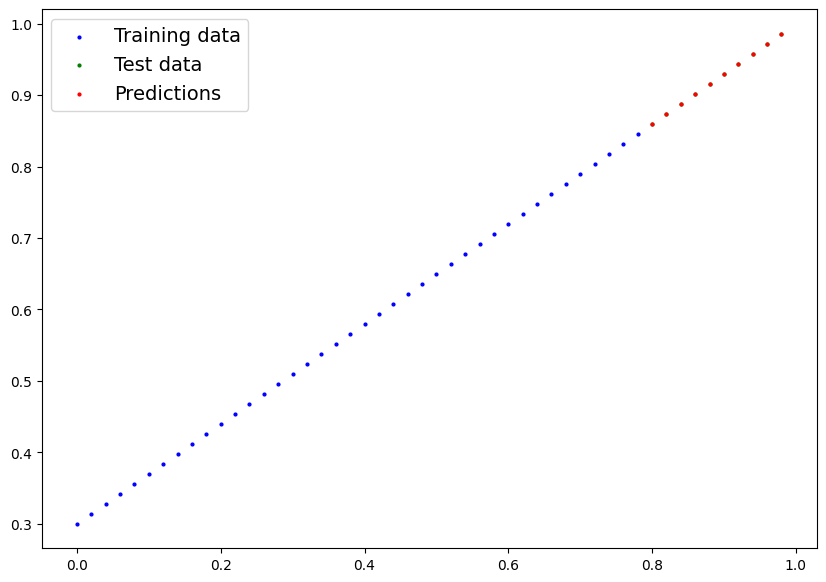

In [16]:
#chekc out our model predictions visually
plot_predictions(predictions=y_preds.cpu())

### 6.5 Saving & loading a trained model

In [18]:
from pathlib import Path

#1. Create models directory
MODEL_PATH=Path("models")
MODEL_PATH.mkdir(parents=True,exist_ok=True)

#2. Create model save path
MODEL_NAME="01_pytorch_workflow_model_1.pth"
MODEL_SAVE_PATH=MODEL_PATH /MODEL_NAME

#3. Save the model state dict
print(f"Saving model to:{MODEL_SAVE_PATH}")
torch.save(obj=model_1.state_dict(),f=MODEL_SAVE_PATH)



Saving model to:models/01_pytorch_workflow_model_1.pth


In [19]:
model_1.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.6968]], device='cuda:0')),
             ('linear_layer.bias', tensor([0.3025], device='cuda:0'))])

In [20]:
#Load a Pytorch model

#Create a new instance of linear regression model v2
loaded_model_1=LinearRegressionModelV2()

#Load the saved model_1 state_dict
loaded_model_1.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

#Put the loaded model to device
loaded_model_1.to(device)

LinearRegressionModelV2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)

In [21]:
next(loaded_model_1.parameters()).device

device(type='cuda', index=0)

In [22]:
loaded_model_1.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.6968]], device='cuda:0')),
             ('linear_layer.bias', tensor([0.3025], device='cuda:0'))])

In [23]:
#Evaluate loaded model
loaded_model_1.eval()
with torch.inference_mode():
  loaded_model_1_preds=loaded_model_1(X_test)

y_preds==loaded_model_1_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]], device='cuda:0')

## Extra-currriculum

- Listen to [The Unofficial PyTorch Optimization Loop Song](https://youtu.be/Nutpusq_AFw) (to help remember the steps in a PyTorch training/testing loop).

- Read [What is `torch.nn`, really?](https://docs.pytorch.org/tutorials/beginner/nn_tutorial.html) by Jeremy Howard for a deeper understanding of how one of the most important modules in PyTorch works.

- Spend 10-minutes scrolling through and checking out the [PyTorch documentation cheatsheet](https://docs.pytorch.org/tutorials/beginner/ptcheat.html) for all of the different PyTorch modules you might come across.

- Spend 10-minutes reading the [loading and saving documentation on the PyTorch website](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html) to become more familiar with the different saving and loading options in PyTorch.

- Spend 1-2 hours reading/watching the following for an overview of the internals of gradient descent and backpropagation, the two main algorithms that have been working in the background to help our model learn.

- [Wikipedia page for gradient descent](https://en.wikipedia.org/wiki/Gradient_descent)

- [Gradient Descent Algorithm – a deep dive](https://robertkwiatkowski.com/gradient-descent-algorithm/) by Robert Kwiatkowski

- [Gradient descent, how neural networks learn](https://youtu.be/IHZwWFHWa-w) video by 3Blue1Brown

- [What is backpropagation really doing?](https://youtu.be/Ilg3gGewQ5U) video by 3Blue1Brown

- [Backpropagation Wikipedia Page](https://en.wikipedia.org/wiki/Backpropagation)